In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="darkgrid", palette="muted")
plt.rcParams["figure.dpi"] = 120

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [15]:
# ── 1. Load Data ──────────────────────────────────────────────────────────────
df = pd.read_csv("../data/raw/stocks/GSPC_2018_2024.csv", parse_dates=["Date"])
df.sort_values("Date", inplace=True)
df.reset_index(drop=True, inplace=True)

print("Shape         :", df.shape)
print("Date Range    :", df["Date"].min().date(), "→", df["Date"].max().date())
print("Columns       :", df.columns.tolist())
df.head(10)

Shape         : (1552, 8)
Date Range    : 2018-01-02 → 2024-03-04
Columns       : ['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Dividends', 'Stock Splits']


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2018-01-02,2683.729980,2695.889893,2682.360107,2695.810059,3397430000,0.0,0.0
1,2018-01-03,2697.850098,2714.370117,2697.770020,2713.060059,3544030000,0.0,0.0
2,2018-01-04,2719.310059,2729.290039,2719.070068,2723.989990,3697340000,0.0,0.0
3,2018-01-05,2731.330078,2743.449951,2727.919922,2743.149902,3239280000,0.0,0.0
4,2018-01-08,2742.669922,2748.510010,2737.600098,2747.709961,3246160000,0.0,0.0
5,2018-01-09,2751.149902,2759.139893,2747.860107,2751.290039,3467460000,0.0,0.0
6,2018-01-10,2745.550049,2750.800049,2736.060059,2748.229980,3579900000,0.0,0.0
7,2018-01-11,2752.969971,2767.560059,2752.780029,2767.560059,3645690000,0.0,0.0
8,2018-01-12,2770.179932,2787.850098,2769.639893,2786.239990,3587220000,0.0,0.0
9,2018-01-16,2798.959961,2807.540039,2768.639893,2776.419922,4362880000,0.0,0.0


In [16]:
# ── 2. Info & Missing Values ──────────────────────────────────────────────────
print("=== DataFrame Info ===")
df.info()
print("\n=== Missing Values ===")
print(df.isnull().sum())
print("\n=== Duplicate Rows ===", df.duplicated().sum())

=== DataFrame Info ===
<class 'pandas.DataFrame'>
RangeIndex: 1552 entries, 0 to 1551
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Date          1552 non-null   datetime64[us]
 1   Open          1552 non-null   float64       
 2   High          1552 non-null   float64       
 3   Low           1552 non-null   float64       
 4   Close         1552 non-null   float64       
 5   Volume        1552 non-null   int64         
 6   Dividends     1552 non-null   float64       
 7   Stock Splits  1552 non-null   float64       
dtypes: datetime64[us](1), float64(6), int64(1)
memory usage: 97.1 KB

=== Missing Values ===
Date            0
Open            0
High            0
Low             0
Close           0
Volume          0
Dividends       0
Stock Splits    0
dtype: int64

=== Duplicate Rows === 0


In [17]:
# ── 3. Descriptive Statistics ─────────────────────────────────────────────────
desc = df[["Open", "High", "Low", "Close", "Volume"]].describe().T
desc["cv%"] = (desc["std"] / desc["mean"] * 100).round(2)  # coefficient of variation
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,cv%
Open,1552.0,3.624000e+03,7.154000e+02,2290.71,2.901300e+03,3.729670e+03,4.257560e+03,5.130990e+03,19.74
High,1552.0,3.645430e+03,7.180300e+02,2300.73,2.909630e+03,3.759040e+03,4.286670e+03,5.149670e+03,19.70
Low,1552.0,3.601240e+03,7.135700e+02,2191.86,2.885020e+03,3.705510e+03,4.221790e+03,5.127180e+03,19.81
Close,1552.0,3.624700e+03,7.162300e+02,2237.40,2.896730e+03,3.729540e+03,4.262780e+03,5.137080e+03,19.76
Volume,1552.0,4.187904e+09,1.035816e+09,0.00,3.549760e+09,3.966020e+09,4.560940e+09,9.976520e+09,24.73


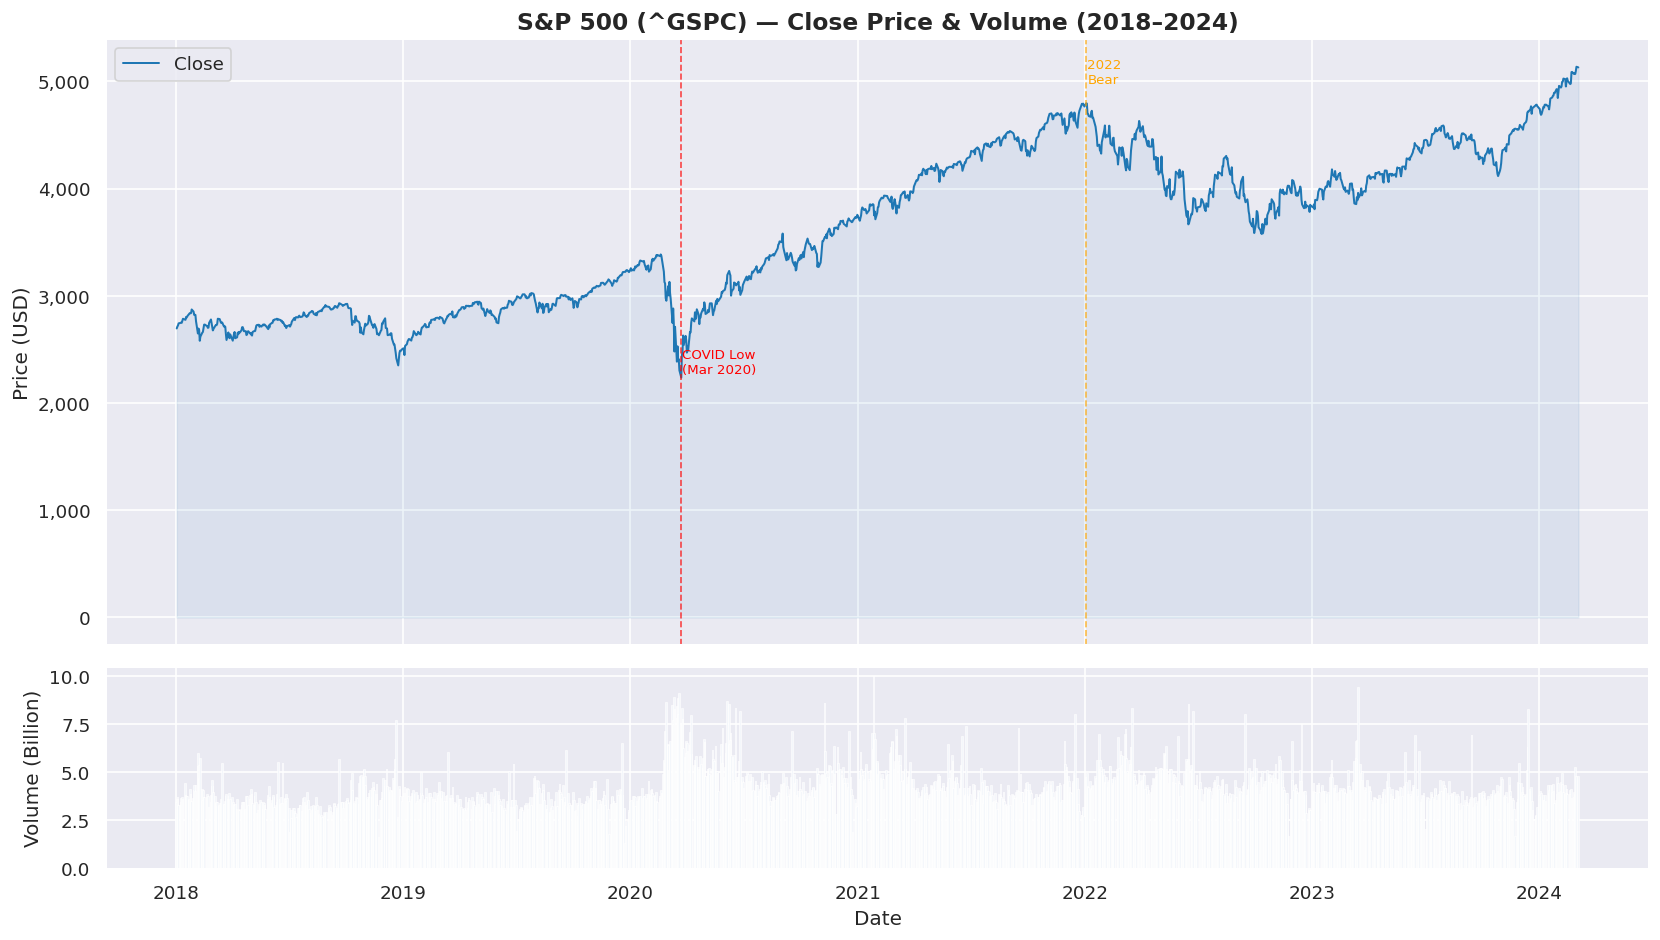

Plot saved.


In [18]:
# ── 4. Harga Close + Volume (Time Series) ─────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                                gridspec_kw={"height_ratios": [3, 1]})

# Close price
ax1.plot(df["Date"], df["Close"], color="#1f77b4", linewidth=1.2, label="Close")
ax1.fill_between(df["Date"], df["Close"], alpha=0.08, color="#1f77b4")
ax1.set_title("S&P 500 (^GSPC) — Close Price & Volume (2018–2024)", fontsize=14, fontweight="bold")
ax1.set_ylabel("Price (USD)")
ax1.legend(loc="upper left")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))

# Annotate COVID crash & recovery
ax1.axvline(pd.Timestamp("2020-03-23"), color="red",   linestyle="--", alpha=0.7, linewidth=1)
ax1.axvline(pd.Timestamp("2022-01-03"), color="orange", linestyle="--", alpha=0.7, linewidth=1)
ax1.text(pd.Timestamp("2020-03-25"), df["Close"].min()*1.02, "COVID Low\n(Mar 2020)",
         color="red", fontsize=8)
ax1.text(pd.Timestamp("2022-01-05"), df["Close"].max()*0.97, "2022\nBear",
         color="orange", fontsize=8)

# Volume
ax2.bar(df["Date"], df["Volume"] / 1e9, color="#aec7e8", width=1.2, alpha=0.85)
ax2.set_ylabel("Volume (Billion)")
ax2.set_xlabel("Date")
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax2.xaxis.set_major_locator(mdates.YearLocator())

plt.tight_layout()
plt.savefig("../data/artifacts/eda_close_volume.png", bbox_inches="tight")
plt.show()
print("Plot saved.")

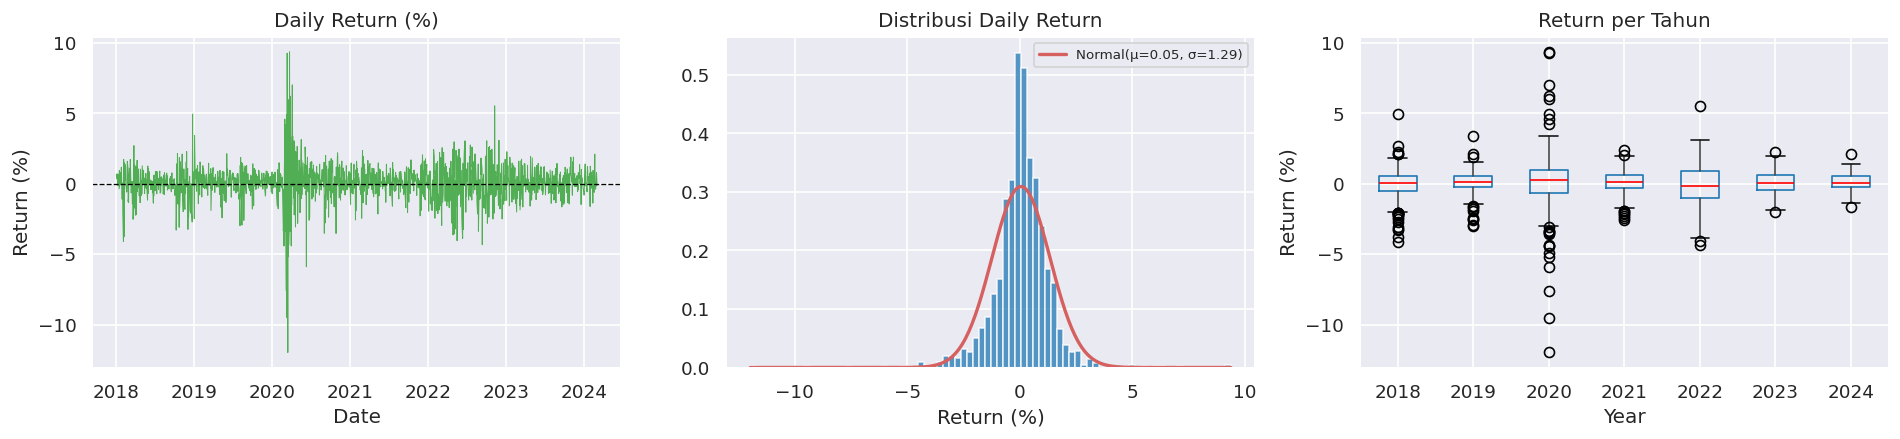

Mean Return : 0.0499%
Std Dev     : 1.2896%
Skewness    : -0.5124
Kurtosis    : 12.9241
Max Gain    : 9.38%  (2020-03-24)
Max Loss    : -11.98%  (2020-03-16)


In [19]:
# ── 5. Daily Returns & Distribusi ─────────────────────────────────────────────
df["Daily_Return"] = df["Close"].pct_change() * 100

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Time series return
axes[0].plot(df["Date"], df["Daily_Return"], color="#2ca02c", linewidth=0.6, alpha=0.8)
axes[0].axhline(0, color="black", linewidth=0.8, linestyle="--")
axes[0].set_title("Daily Return (%)")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Return (%)")

# Histogram + KDE
axes[1].hist(df["Daily_Return"].dropna(), bins=80, color="#1f77b4",
             edgecolor="white", alpha=0.75, density=True)
mu, sigma = df["Daily_Return"].mean(), df["Daily_Return"].std()
x = np.linspace(df["Daily_Return"].min(), df["Daily_Return"].max(), 300)
axes[1].plot(x, stats.norm.pdf(x, mu, sigma), "r-", lw=2, label=f"Normal(μ={mu:.2f}, σ={sigma:.2f})")
axes[1].legend(fontsize=8)
axes[1].set_title("Distribusi Daily Return")
axes[1].set_xlabel("Return (%)")

# Box plot per tahun
df["Year"] = df["Date"].dt.year
df.boxplot(column="Daily_Return", by="Year", ax=axes[2], 
           boxprops=dict(color="#1f77b4"), medianprops=dict(color="red"))
axes[2].set_title("Return per Tahun")
axes[2].set_xlabel("Year")
axes[2].set_ylabel("Return (%)")
plt.suptitle("")

plt.tight_layout()
plt.savefig("../data/artifacts/eda_daily_return.png", bbox_inches="tight")
plt.show()

print(f"Mean Return : {mu:.4f}%")
print(f"Std Dev     : {sigma:.4f}%")
print(f"Skewness    : {df['Daily_Return'].skew():.4f}")
print(f"Kurtosis    : {df['Daily_Return'].kurt():.4f}")
print(f"Max Gain    : {df['Daily_Return'].max():.2f}%  ({df.loc[df['Daily_Return'].idxmax(), 'Date'].date()})")
print(f"Max Loss    : {df['Daily_Return'].min():.2f}%  ({df.loc[df['Daily_Return'].idxmin(), 'Date'].date()})")

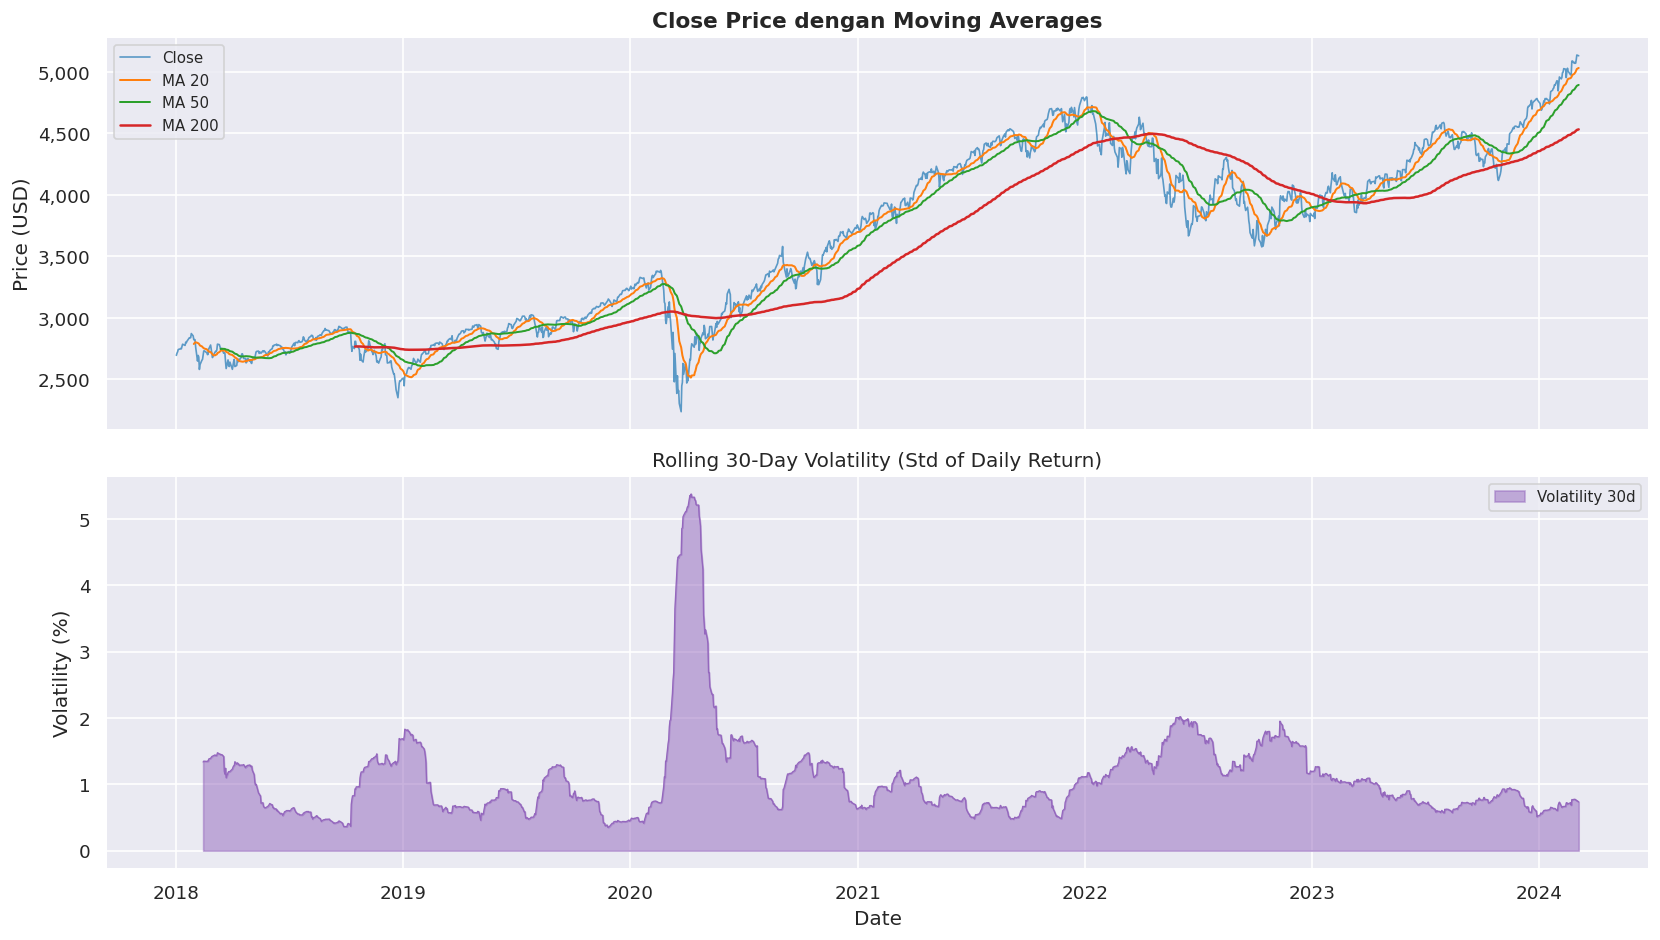

Plot saved.


In [20]:
# ── 6. Rolling Statistics (MA & Volatility) ───────────────────────────────────
df["MA_20"]  = df["Close"].rolling(20).mean()
df["MA_50"]  = df["Close"].rolling(50).mean()
df["MA_200"] = df["Close"].rolling(200).mean()
df["Vol_30"] = df["Daily_Return"].rolling(30).std()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Price + Moving Averages
ax1.plot(df["Date"], df["Close"],  color="#1f77b4", lw=1,   label="Close",  alpha=0.7)
ax1.plot(df["Date"], df["MA_20"],  color="#ff7f0e", lw=1.2, label="MA 20")
ax1.plot(df["Date"], df["MA_50"],  color="#2ca02c", lw=1.2, label="MA 50")
ax1.plot(df["Date"], df["MA_200"], color="#d62728", lw=1.5, label="MA 200")
ax1.set_title("Close Price dengan Moving Averages", fontsize=13, fontweight="bold")
ax1.set_ylabel("Price (USD)")
ax1.legend(loc="upper left", fontsize=9)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))

# Rolling Volatility
ax2.fill_between(df["Date"], df["Vol_30"], color="#9467bd", alpha=0.5, label="Volatility 30d")
ax2.plot(df["Date"], df["Vol_30"], color="#9467bd", lw=0.8)
ax2.set_title("Rolling 30-Day Volatility (Std of Daily Return)", fontsize=12)
ax2.set_ylabel("Volatility (%)")
ax2.set_xlabel("Date")
ax2.legend(fontsize=9)

plt.tight_layout()
plt.savefig("../data/artifacts/eda_ma_volatility.png", bbox_inches="tight")
plt.show()
print("Plot saved.")

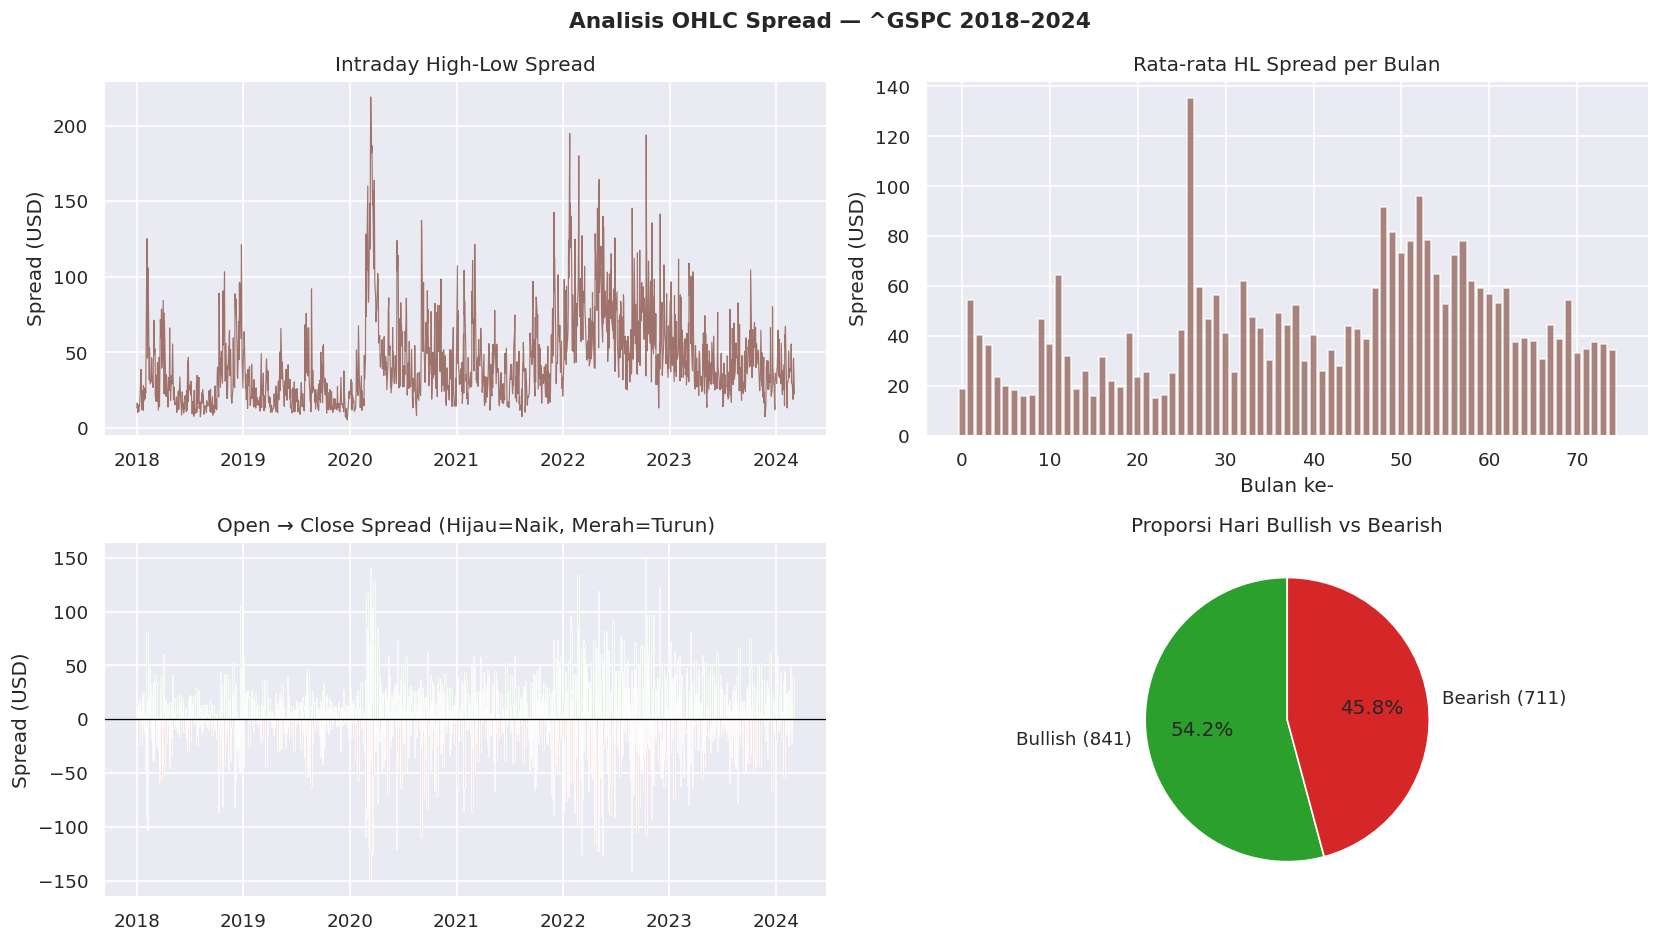

Plot saved.


In [21]:
# ── 7. Candlestick-style OHLC Range & Spread ──────────────────────────────────
df["HL_Spread"] = df["High"] - df["Low"]        # intraday range
df["OC_Spread"] = df["Close"] - df["Open"]      # open-to-close direction

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# High-Low Spread over time
axes[0, 0].plot(df["Date"], df["HL_Spread"], color="#8c564b", lw=0.7, alpha=0.8)
axes[0, 0].set_title("Intraday High-Low Spread")
axes[0, 0].set_ylabel("Spread (USD)")

# Monthly avg HL Spread
monthly_hl = df.groupby(df["Date"].dt.to_period("M"))["HL_Spread"].mean()
axes[0, 1].bar(range(len(monthly_hl)), monthly_hl.values, color="#8c564b", alpha=0.7)
axes[0, 1].set_title("Rata-rata HL Spread per Bulan")
axes[0, 1].set_xlabel("Bulan ke-")
axes[0, 1].set_ylabel("Spread (USD)")

# Open-Close direction distribution
colors = ["#2ca02c" if v >= 0 else "#d62728" for v in df["OC_Spread"]]
axes[1, 0].bar(df["Date"], df["OC_Spread"], color=colors, width=1.5, alpha=0.85)
axes[1, 0].axhline(0, color="black", linewidth=0.8)
axes[1, 0].set_title("Open → Close Spread (Hijau=Naik, Merah=Turun)")
axes[1, 0].set_ylabel("Spread (USD)")

# Pie chart: bullish vs bearish days
bullish = (df["OC_Spread"] > 0).sum()
bearish = (df["OC_Spread"] <= 0).sum()
axes[1, 1].pie([bullish, bearish],
               labels=[f"Bullish ({bullish})", f"Bearish ({bearish})"],
               colors=["#2ca02c", "#d62728"], autopct="%1.1f%%",
               startangle=90, wedgeprops={"edgecolor": "white"})
axes[1, 1].set_title("Proporsi Hari Bullish vs Bearish")

plt.suptitle("Analisis OHLC Spread — ^GSPC 2018–2024", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../data/artifacts/eda_ohlc_spread.png", bbox_inches="tight")
plt.show()
print("Plot saved.")

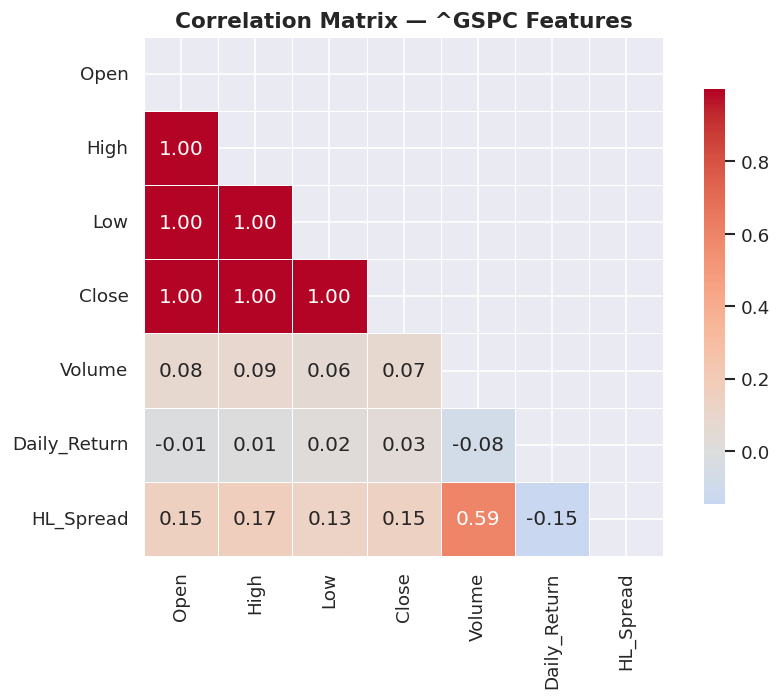

Plot saved.


In [22]:
# ── 8. Korelasi Antar Fitur ───────────────────────────────────────────────────
corr_cols = ["Open", "High", "Low", "Close", "Volume", "Daily_Return", "HL_Spread"]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True, linewidths=0.5, ax=ax,
            cbar_kws={"shrink": 0.8})
ax.set_title("Correlation Matrix — ^GSPC Features", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../data/artifacts/eda_correlation.png", bbox_inches="tight")
plt.show()
print("Plot saved.")

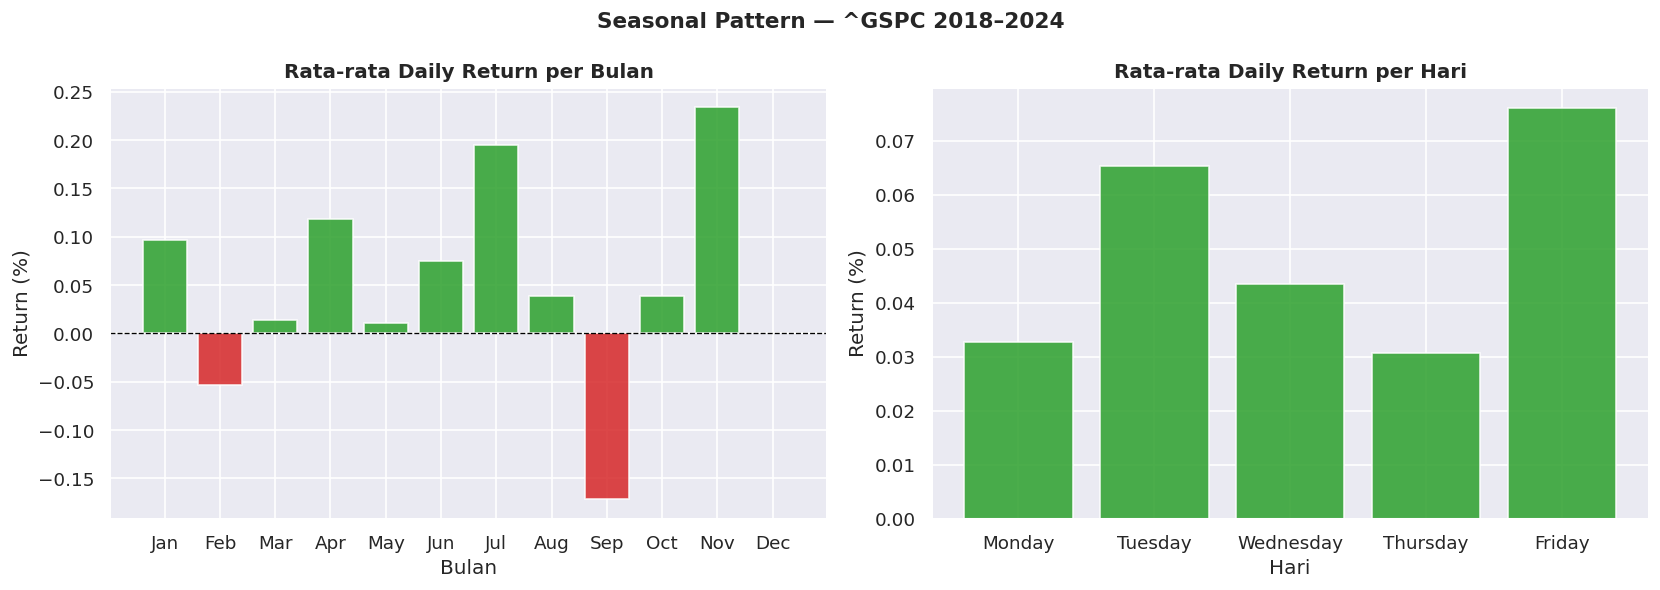

Plot saved.


In [23]:
# ── 9. Analisis Musiman: Return per Bulan & Hari dalam Seminggu ───────────────
df["Month"]    = df["Date"].dt.month
df["DayOfWeek"] = df["Date"].dt.day_name()

monthly_ret  = df.groupby("Month")["Daily_Return"].mean()
weekday_ret  = df.groupby("DayOfWeek")["Daily_Return"].mean()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
weekday_ret   = weekday_ret.reindex(weekday_order)
month_names   = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Per bulan
colors_m = ["#2ca02c" if v >= 0 else "#d62728" for v in monthly_ret]
ax1.bar(month_names, monthly_ret.values, color=colors_m, edgecolor="white", alpha=0.85)
ax1.axhline(0, color="black", lw=0.8, linestyle="--")
ax1.set_title("Rata-rata Daily Return per Bulan", fontsize=12, fontweight="bold")
ax1.set_ylabel("Return (%)")
ax1.set_xlabel("Bulan")

# Per hari
colors_d = ["#2ca02c" if v >= 0 else "#d62728" for v in weekday_ret]
ax2.bar(weekday_ret.index, weekday_ret.values, color=colors_d, edgecolor="white", alpha=0.85)
ax2.axhline(0, color="black", lw=0.8, linestyle="--")
ax2.set_title("Rata-rata Daily Return per Hari", fontsize=12, fontweight="bold")
ax2.set_ylabel("Return (%)")
ax2.set_xlabel("Hari")

plt.suptitle("Seasonal Pattern — ^GSPC 2018–2024", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../data/artifacts/eda_seasonal.png", bbox_inches="tight")
plt.show()
print("Plot saved.")

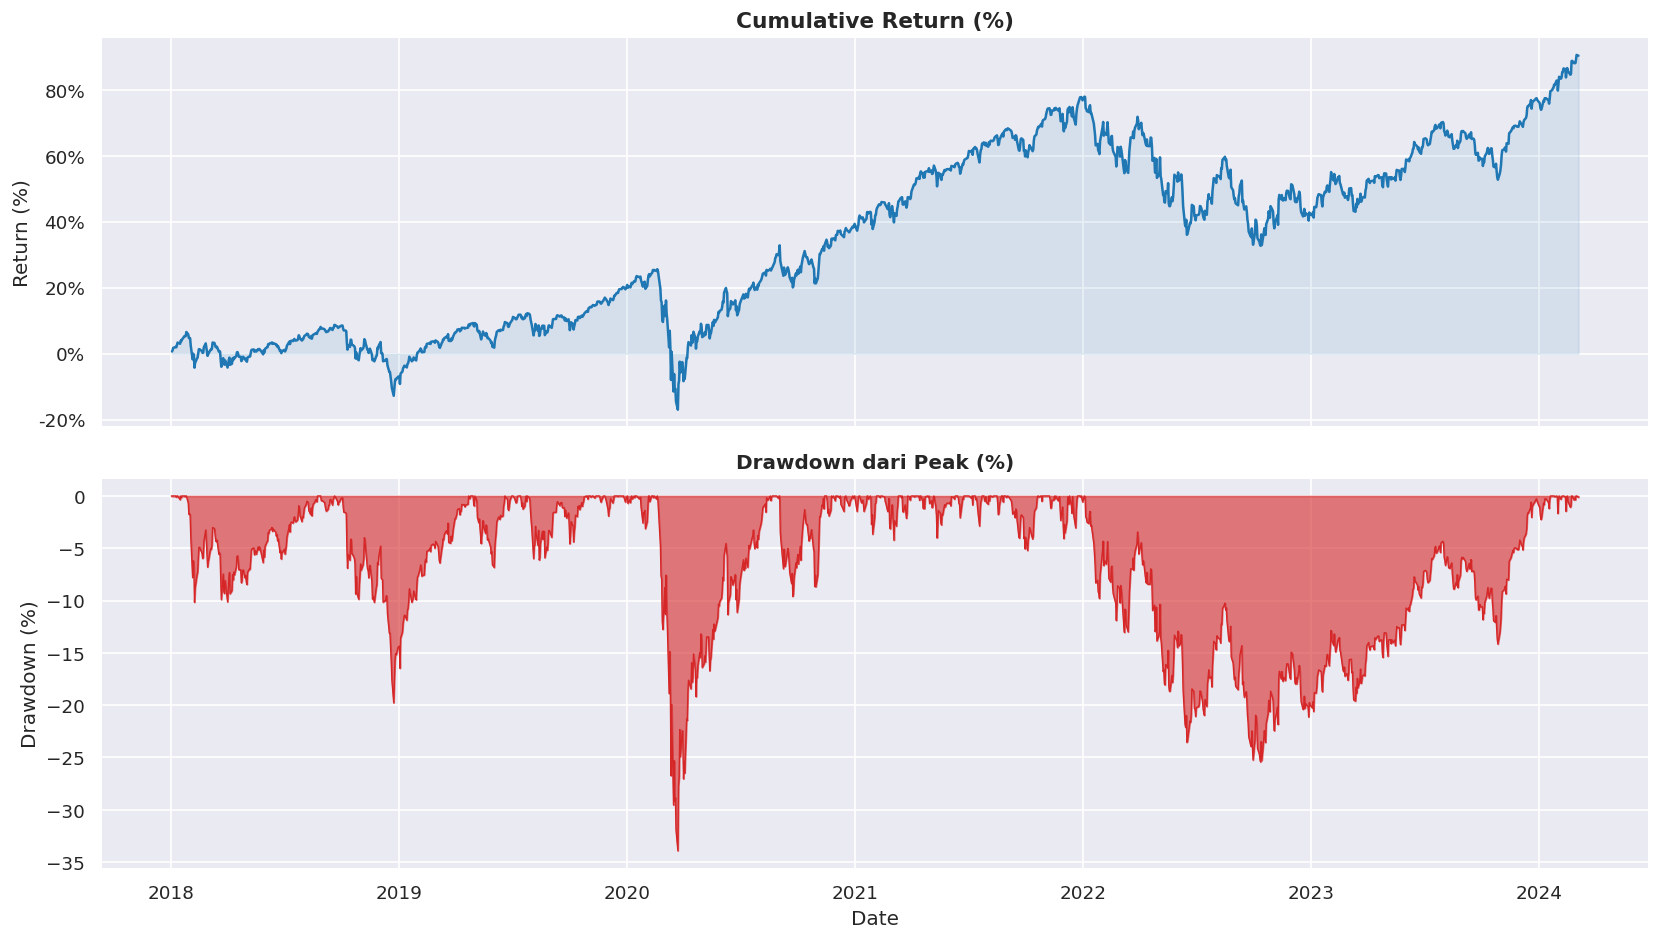

Total Cumulative Return : 90.33%
Maximum Drawdown        : -33.92%


In [24]:
# ── 10. Cumulative Return & Drawdown ──────────────────────────────────────────
df["Cum_Return"]   = (1 + df["Daily_Return"] / 100).cumprod() - 1
rolling_max        = df["Close"].cummax()
df["Drawdown"]     = (df["Close"] - rolling_max) / rolling_max * 100

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Cumulative return
ax1.plot(df["Date"], df["Cum_Return"] * 100, color="#1f77b4", lw=1.5)
ax1.fill_between(df["Date"], df["Cum_Return"] * 100, alpha=0.1, color="#1f77b4")
ax1.set_title("Cumulative Return (%)", fontsize=13, fontweight="bold")
ax1.set_ylabel("Return (%)")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0f}%"))

# Drawdown
ax2.fill_between(df["Date"], df["Drawdown"], color="#d62728", alpha=0.6)
ax2.plot(df["Date"], df["Drawdown"], color="#d62728", lw=0.8)
ax2.set_title("Drawdown dari Peak (%)", fontsize=12, fontweight="bold")
ax2.set_ylabel("Drawdown (%)")
ax2.set_xlabel("Date")

plt.tight_layout()
plt.savefig("../data/artifacts/eda_cumreturn_drawdown.png", bbox_inches="tight")
plt.show()

total_ret  = df["Cum_Return"].iloc[-1] * 100
max_dd     = df["Drawdown"].min()
print(f"Total Cumulative Return : {total_ret:.2f}%")
print(f"Maximum Drawdown        : {max_dd:.2f}%")

In [25]:
# ── 11. Ringkasan Statistik Akhir ─────────────────────────────────────────────
annual_ret = df.groupby("Year")["Daily_Return"].apply(lambda x: (1 + x/100).prod() - 1) * 100

print("=" * 50)
print("     RINGKASAN EDA — ^GSPC 2018–2024")
print("=" * 50)
print(f"  Total Trading Days : {len(df):,}")
print(f"  Harga Awal (Close) : {df['Close'].iloc[0]:,.2f}")
print(f"  Harga Akhir (Close): {df['Close'].iloc[-1]:,.2f}")
print(f"  Cum. Return        : +{total_ret:.2f}%")
print(f"  Max Drawdown       : {max_dd:.2f}%")
print(f"  Mean Daily Return  : {df['Daily_Return'].mean():.4f}%")
print(f"  Volatility (ann.)  : {df['Daily_Return'].std() * (252**0.5):.2f}%")
print(f"  Skewness           : {df['Daily_Return'].skew():.4f} (negatif = ekor kiri)")
print(f"  Kurtosis           : {df['Daily_Return'].kurt():.4f} (> 3 = leptokurtik)")
print(f"  Hari Bullish       : {bullish} ({bullish/len(df)*100:.1f}%)")
print(f"  Hari Bearish       : {bearish} ({bearish/len(df)*100:.1f}%)")
print()
print("  Return per Tahun:")
for yr, r in annual_ret.items():
    bar = "█" * int(abs(r) / 2)
    sign = "+" if r >= 0 else ""
    print(f"    {yr}: {sign}{r:.2f}%  {bar}")
print("=" * 50)

     RINGKASAN EDA — ^GSPC 2018–2024
  Total Trading Days : 1,552
  Harga Awal (Close) : 2,695.81
  Harga Akhir (Close): 5,130.95
  Cum. Return        : +90.33%
  Max Drawdown       : -33.92%
  Mean Daily Return  : 0.0499%
  Volatility (ann.)  : 20.47%
  Skewness           : -0.5124 (negatif = ekor kiri)
  Kurtosis           : 12.9241 (> 3 = leptokurtik)
  Hari Bullish       : 841 (54.2%)
  Hari Bearish       : 711 (45.8%)

  Return per Tahun:
    2018: -7.01%  ███
    2019: +28.88%  ██████████████
    2020: +16.26%  ████████
    2021: +26.89%  █████████████
    2022: -19.44%  █████████
    2023: +24.23%  ████████████
    2024: +7.57%  ███


## Feature Engineering & Data Processing

Membangun dataset terproses dengan menghapus kolom tidak relevan dan menambahkan fitur turunan.

In [26]:
import pandas as pd
import numpy as np

# Load raw data
df = pd.read_csv("../data/raw/stocks/GSPC_2018_2024.csv", parse_dates=["Date"])
df.sort_values("Date", inplace=True)
df.reset_index(drop=True, inplace=True)

# Drop kolom tidak relevan
df.drop(columns=["Dividends", "Stock Splits"], inplace=True)

# Tambah fitur turunan
df["Daily_Return"]  = df["Close"].pct_change() * 100
df["HL_Spread"]     = df["High"] - df["Low"]
df["OC_Spread"]     = df["Close"] - df["Open"]
df["MA_20"]         = df["Close"].rolling(20).mean()
df["Volatility_30"] = df["Daily_Return"].rolling(30).std()

# Simpan ke processed
out_path = "../data/processed/stocks/GSPC_2018_2024.csv"
df.to_csv(out_path, index=False)

print(f"Shape       : {df.shape}")
print(f"Kolom       : {df.columns.tolist()}")
print(f"Missing vals:\n{df.isnull().sum()}")
print(f"\nFile disimpan → {out_path}")

Shape       : (1552, 11)
Kolom       : ['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Daily_Return', 'HL_Spread', 'OC_Spread', 'MA_20', 'Volatility_30']
Missing vals:
Date              0
Open              0
High              0
Low               0
Close             0
Volume            0
Daily_Return      1
HL_Spread         0
OC_Spread         0
MA_20            19
Volatility_30    30
dtype: int64

File disimpan → ../data/processed/stocks/GSPC_2018_2024.csv


In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="darkgrid", palette="muted")
plt.rcParams["figure.dpi"] = 120

print("Libraries loaded successfully.")

Libraries loaded successfully.


# Kesimpulan EDA — S&P 500 ^GSPC (2018–2024)

## Temuan Utama

### 1. Tren Harga
- Harga Close naik dari **2.695** → **5.130** (gain **+90.33%** selama 6 tahun)
- Terdapat dua periode koreksi besar: **COVID-19 (Mar 2020)** dan **Bear Market 2022**

### 2. Return & Volatilitas
| Metrik | Nilai |
|--------|-------|
| Mean Daily Return | +0.05% |
| Volatilitas Tahunan | 20.47% |
| Max Gain 1 Hari | +9.38% (24 Mar 2020) |
| Max Loss 1 Hari | -11.98% (16 Mar 2020) |
| Maximum Drawdown | -33.92% |

### 3. Distribusi Return
- **Skewness negatif (-0.51)** → ekor kiri lebih panjang, artinya crash lebih ekstrem dari rally
- **Kurtosis tinggi (12.92)** → distribusi *leptokurtik* (fat tails), return ekstrem lebih sering dari normal

### 4. Pola Musiman
- **Bulan terbaik:** November (+0.23%), Juli (+0.20%)
- **Bulan terburuk:** September (-0.16%), Februari (-0.04%)
- **Hari terbaik:** Jumat & Selasa secara rata-rata

### 5. Korelasi
- OHLC saling berkorelasi sangat tinggi (~1.0)
- Volume berkorelasi moderat dengan HL Spread (0.59) → volume besar = intraday range lebih lebar

## Implikasi untuk Model Prediksi
- Data **bersih** (0 missing values, 0 duplikat) — siap preprocessing
- Volatility clustering terlihat jelas → LSTM diharapkan bisa menangkap pola ini
- Distribusi fat-tails perlu diperhatikan saat normalisasi fitur (pertimbangkan `RobustScaler`)
